# Box Plots, Outliers & Distribution Comparisons
**Course Notes Reference:** Parts 8 & 15

Topics covered:
1. Anatomy of a Box Plot (Min, Q1, Median, Q3, Max, IQR, Outliers)
2. Detecting Outliers with the **IQR Rule** (`Q1 - 1.5*IQR` to `Q3 + 1.5*IQR`)
3. Detecting Outliers with **Z-Score** (`|z| > 3`)
4. Percentiles (`quantile`) & `describe()`
5. Numerical vs Categorical: Box plot & Violin plot per Genre
6. Why log scale helps when comparing skewed sales across categories


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("vgsales.csv").dropna(subset=["Year", "Publisher"]).copy()
df["Year"] = df["Year"].astype(int)
df["Global_Sales"].describe()


## 1. Basic Box Plot of `Global_Sales`


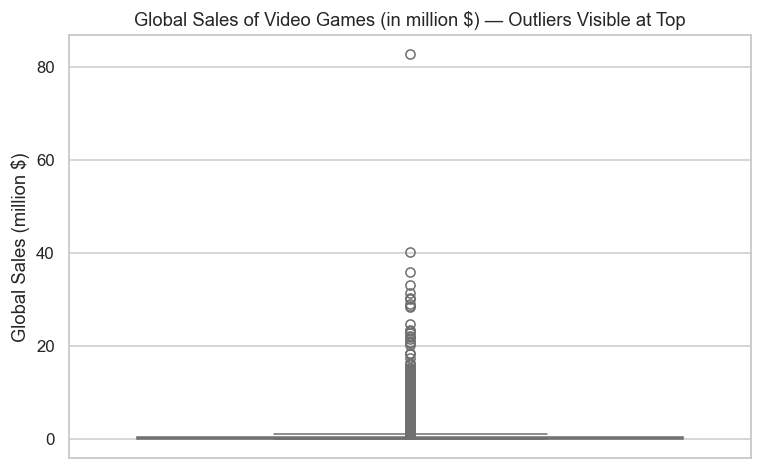

In [2]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=df["Global_Sales"], color="skyblue")
plt.title("Global Sales of Video Games (in million $) — Outliers Visible at Top")
plt.ylabel("Global Sales (million $)")
plt.show()


## 2. Finding Outliers with the IQR Rule & Z-Score


In [3]:
q1 = df["Global_Sales"].quantile(0.25)
q3 = df["Global_Sales"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

iqr_outliers = df[(df["Global_Sales"] < lower) | (df["Global_Sales"] > upper)]
print(f"Q1 = {q1:.2f}, Median = {df['Global_Sales'].median():.2f}, Q3 = {q3:.2f}, IQR = {iqr:.2f}")
print(f"Upper fence = {upper:.2f} M$")
print(f"IQR outliers count: {len(iqr_outliers)} ({len(iqr_outliers)/len(df)*100:.1f}% of games)")

# Z-score method
z_scores = (df["Global_Sales"] - df["Global_Sales"].mean()) / df["Global_Sales"].std()
z_outliers = df[z_scores.abs() > 3]
print(f"Z-score (|z| > 3) outliers count: {len(z_outliers)}")

print("\nTop 5 blockbuster outliers (real hits, do NOT delete blindly!):")
display(iqr_outliers.sort_values("Global_Sales", ascending=False).head(5)[["Name", "Platform", "Year", "Genre", "Global_Sales"]])


Q1 = 0.06, Median = 0.17, Q3 = 0.48, IQR = 0.42
Upper fence = 1.11 M$
IQR outliers count: 1826 (11.2% of games)
Z-score (|z| > 3) outliers count: 178

Top 5 blockbuster outliers (real hits, do NOT delete blindly!):


                       Name Platform  Year         Genre  Global_Sales
0                Wii Sports      Wii  2006        Sports         82.74
1         Super Mario Bros.      NES  1985      Platform         40.24
2            Mario Kart Wii      Wii  2008        Racing         35.82
3         Wii Sports Resort      Wii  2009        Sports         33.00
4  Pokemon Red/Pokemon Blue       GB  1996  Role-Playing         31.37

## 3. Percentiles in Plain Words


In [4]:
for p in [0.25, 0.50, 0.75, 0.90, 0.99]:
    print(f"{int(p*100)}th percentile: {df['Global_Sales'].quantile(p):.2f} M$")


25th percentile: 0.06 M$
50th percentile: 0.17 M$
75th percentile: 0.48 M$
90th percentile: 1.22 M$
99th percentile: 5.47 M$


## 4. Numerical vs Categorical: Box Plot & Violin Plot per Genre


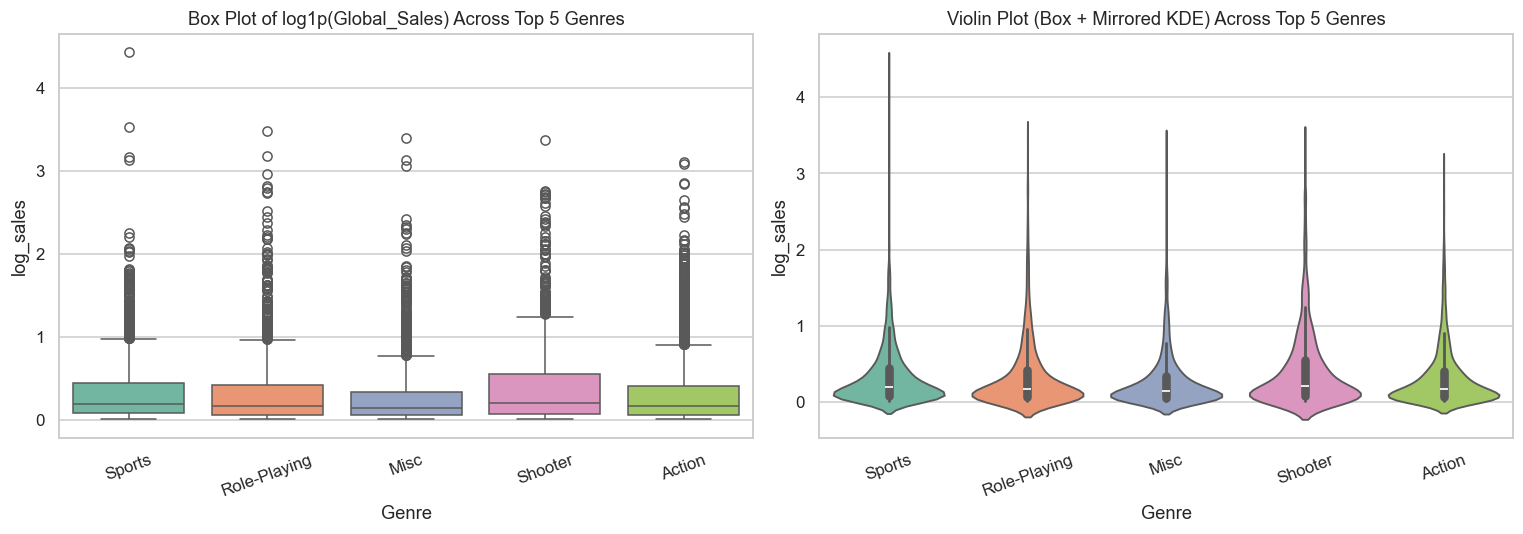

In [5]:
top5_genres = df["Genre"].value_counts().head(5).index
sub = df[df["Genre"].isin(top5_genres)].copy()
sub["log_sales"] = np.log1p(sub["Global_Sales"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(x="Genre", y="log_sales", data=sub, hue="Genre", palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Box Plot of log1p(Global_Sales) Across Top 5 Genres")
axes[0].tick_params(axis="x", rotation=20)

sns.violinplot(x="Genre", y="log_sales", data=sub, hue="Genre", palette="Set2", legend=False, ax=axes[1])
axes[1].set_title("Violin Plot (Box + Mirrored KDE) Across Top 5 Genres")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()
